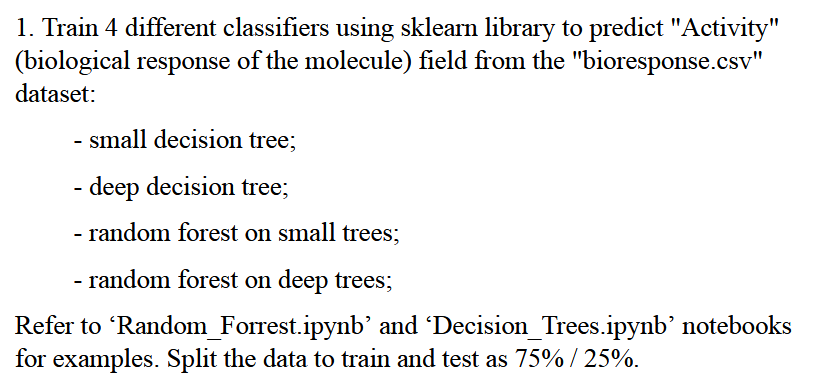

In [3]:
from matplotlib.colors import ListedColormap
from sklearn import  datasets, metrics, tree
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import  learning_curve

import numpy as np
import pandas as pd
import matplotlib as plt

In [4]:
%pylab inline

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


c:\Users\XML100926\dev\ITMO\MLT\task2\.venv\Lib\site-packages\IPython\core\magics\pylab.py:166: UserWarning: pylab import has clobbered these variables: ['plt']
`%matplotlib` prevents importing * from pylab and numpy
  warn("pylab import has clobbered these variables: %s"  % clobbered +


In [5]:
FILENAME = "bioresponse.csv"

bioresponce = pd.read_csv(FILENAME, header=0, sep=',')
bioresponce_data = bioresponce.iloc[:, 1:]
bioresponce_target = bioresponce.Activity.values
bioresponce

,Activity,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,D1767,D1768,D1769,D1770,D1771,D1772,D1773,D1774,D1775,D1776
0,1,0.000000,0.497009,0.10,0.0,0.132956,0.678031,0.273166,0.585445,0.743663,...,0,0,0,0,0,0,0,0,0,0
1,1,0.366667,0.606291,0.05,0.0,0.111209,0.803455,0.106105,0.411754,0.836582,...,1,1,1,1,0,1,0,0,1,0
2,1,0.033300,0.480124,0.00,0.0,0.209791,0.610350,0.356453,0.517720,0.679051,...,0,0,0,0,0,0,0,0,0,0
3,1,0.000000,0.538825,0.00,0.5,0.196344,0.724230,0.235606,0.288764,0.805110,...,0,0,0,0,0,0,0,0,0,0
4,0,0.100000,0.517794,0.00,0.0,0.494734,0.781422,0.154361,0.303809,0.812646,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3746,1,0.033300,0.506409,0.10,0.0,0.209887,0.633426,0.297659,0.376124,0.727093,...,0,0,0,0,0,0,0,0,0,0
3747,1,0.133333,0.651023,0.15,0.0,0.151154,0.766505,0.170876,0.404546,0.787935,...,0,0,1,0,1,0,1,0,0,0
3748,0,0.200000,0.520564,0.00,0.0,0.179949,0.768785,0.177341,0.471179,0.872241,...,0,0,0,0,0,0,0,0,0,0
3749,1,0.100000,0.765646,0.00,0.0,0.536954,0.634936,0.342713,0.447162,0.672689,...,0,0,0,0,0,0,0,0,0,0


In [6]:
bioresponce.columns

Index(['Activity', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9',
       ...
       'D1767', 'D1768', 'D1769', 'D1770', 'D1771', 'D1772', 'D1773', 'D1774',
       'D1775', 'D1776'],
      dtype='str', length=1777)

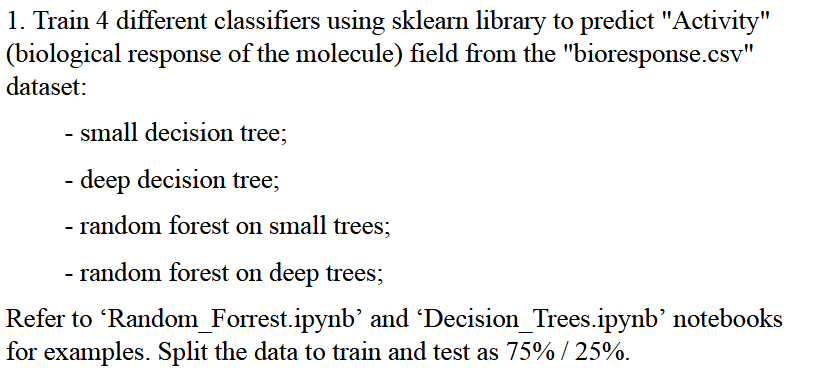

In [7]:
X_train, X_test, y_train, y_test = train_test_split( bioresponce_data, 
                                                    bioresponce_target, 
                                                    test_size=0.25,
                                                    random_state=42)

In [8]:
models = [
#Small decision tree
("Small decision tree", tree.DecisionTreeClassifier(random_state = 1, max_depth = 3)),
# Deep decision tree 
("Deep decision tree", tree.DecisionTreeClassifier(random_state = 1, max_depth = None)),
# Small rforest
("Small random forest", RandomForestClassifier(n_estimators = 50, max_depth = 2, random_state = 1)),
# Deep rforest
("Deep random forest", RandomForestClassifier(n_estimators = 50, max_depth = None, random_state = 1))
]

In [9]:
probabilities = {}
for name, model in models:
    model.fit(X_train, y_train)
    probabilities[name] = model.predict_proba(X_test)[:, 1]

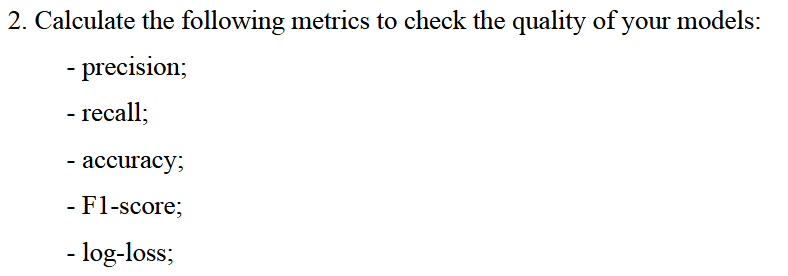

In [10]:
def compute_metrics (y_test, y_proba, trashold = 0.5):
    y_pred = (np.asarray(y_proba) >= trashold).astype(int)
    
    return {
    "precision" : metrics.precision_score(y_test, y_pred),
    "recall" : metrics.recall_score(y_test, y_pred),
    "accuracy" : metrics.accuracy_score(y_test, y_pred),
    "f1 score" : metrics.f1_score(y_test, y_pred),
    "log loss" : metrics.log_loss(y_test, y_proba)
    }

In [11]:
metrics_df = pd.DataFrame(
    {name: compute_metrics(y_test, proba) for name, proba in probabilities.items()}
).T
metrics_df.round(4)

,precision,recall,accuracy,f1 score,log loss
Small decision tree,0.7853,0.8000,0.7612,0.7926,0.5402
Deep decision tree,0.7530,0.7121,0.7026,0.7320,10.7209
Small random forest,0.7160,0.7963,0.7036,0.7540,0.6271
Deep random forest,0.8124,0.8336,0.7953,0.8229,0.4886


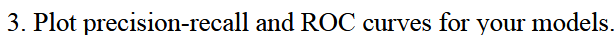

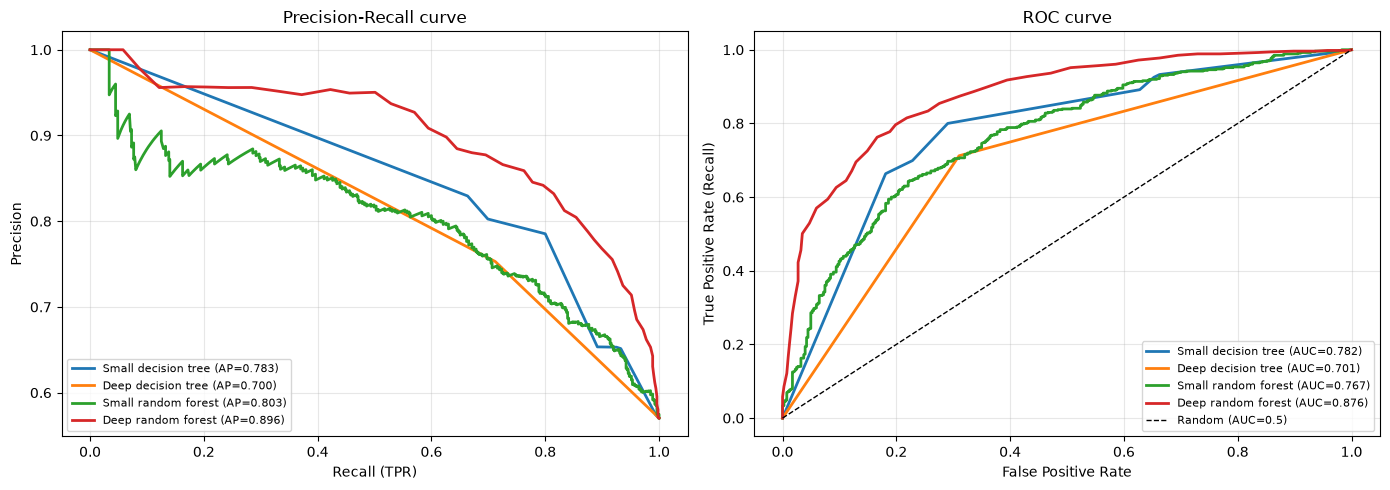

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, proba in probabilities.items():
    precision, recall, _ = metrics.precision_recall_curve(y_test, proba)
    axes[0].plot(recall, precision, lw=2,
                 label=f"{name} (AP={metrics.average_precision_score(y_test, proba):.3f})")

    fpr, tpr, _ = metrics.roc_curve(y_test, proba)
    axes[1].plot(fpr, tpr, lw=2,
                 label=f"{name} (AUC={metrics.roc_auc_score(y_test, proba):.3f})")

axes[0].set(xlabel="Recall (TPR)", ylabel="Precision", title="Precision-Recall curve")
axes[0].legend(loc="lower left", fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Random (AUC=0.5)")
axes[1].set(xlabel="False Positive Rate", ylabel="True Positive Rate (Recall)",
            title="ROC curve")
axes[1].legend(loc="lower right", fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

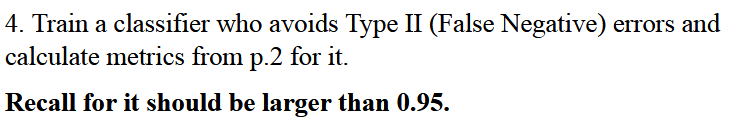

In [13]:
cool_model = RandomForestClassifier(n_estimators = 100, max_depth = None, random_state = 1) 
cool_trashold = 0
cool_depth = "inf"
max_precision = 0

for i in range(10):
    rf = RandomForestClassifier(n_estimators = 100, max_depth =   5 * (i + 1), random_state = 1)
    rf.fit(X_train, y_train)
    y_proba = rf.predict_proba(X_test)[ : , 1]
    for j in range(10, 50, 5):
        trashold = j / 100
        y_pred = (np.asarray(y_proba) >= trashold).astype(int)
        recall = metrics.recall_score(y_test, y_pred)
        precision = metrics.precision_score(y_test, y_pred)
        if recall >= 0.95 and max_precision < precision:
            cool_model = rf
            max_precision = precision
            cool_trashold = trashold
            cool_depth = i
cool_model.fit(X_train, y_train)

print("trashold:", cool_trashold, "depth:", 5 * (cool_depth + 1))
metrics_df = pd.DataFrame(
    {"Модель": compute_metrics(y_test, cool_model.predict_proba(X_test)[:, 1], cool_trashold)}
).T
metrics_df.round(4)

trashold: 0.35 depth: 10


,precision,recall,accuracy,f1 score,log loss
Модель,0.7199,0.9514,0.7612,0.8196,0.4868
